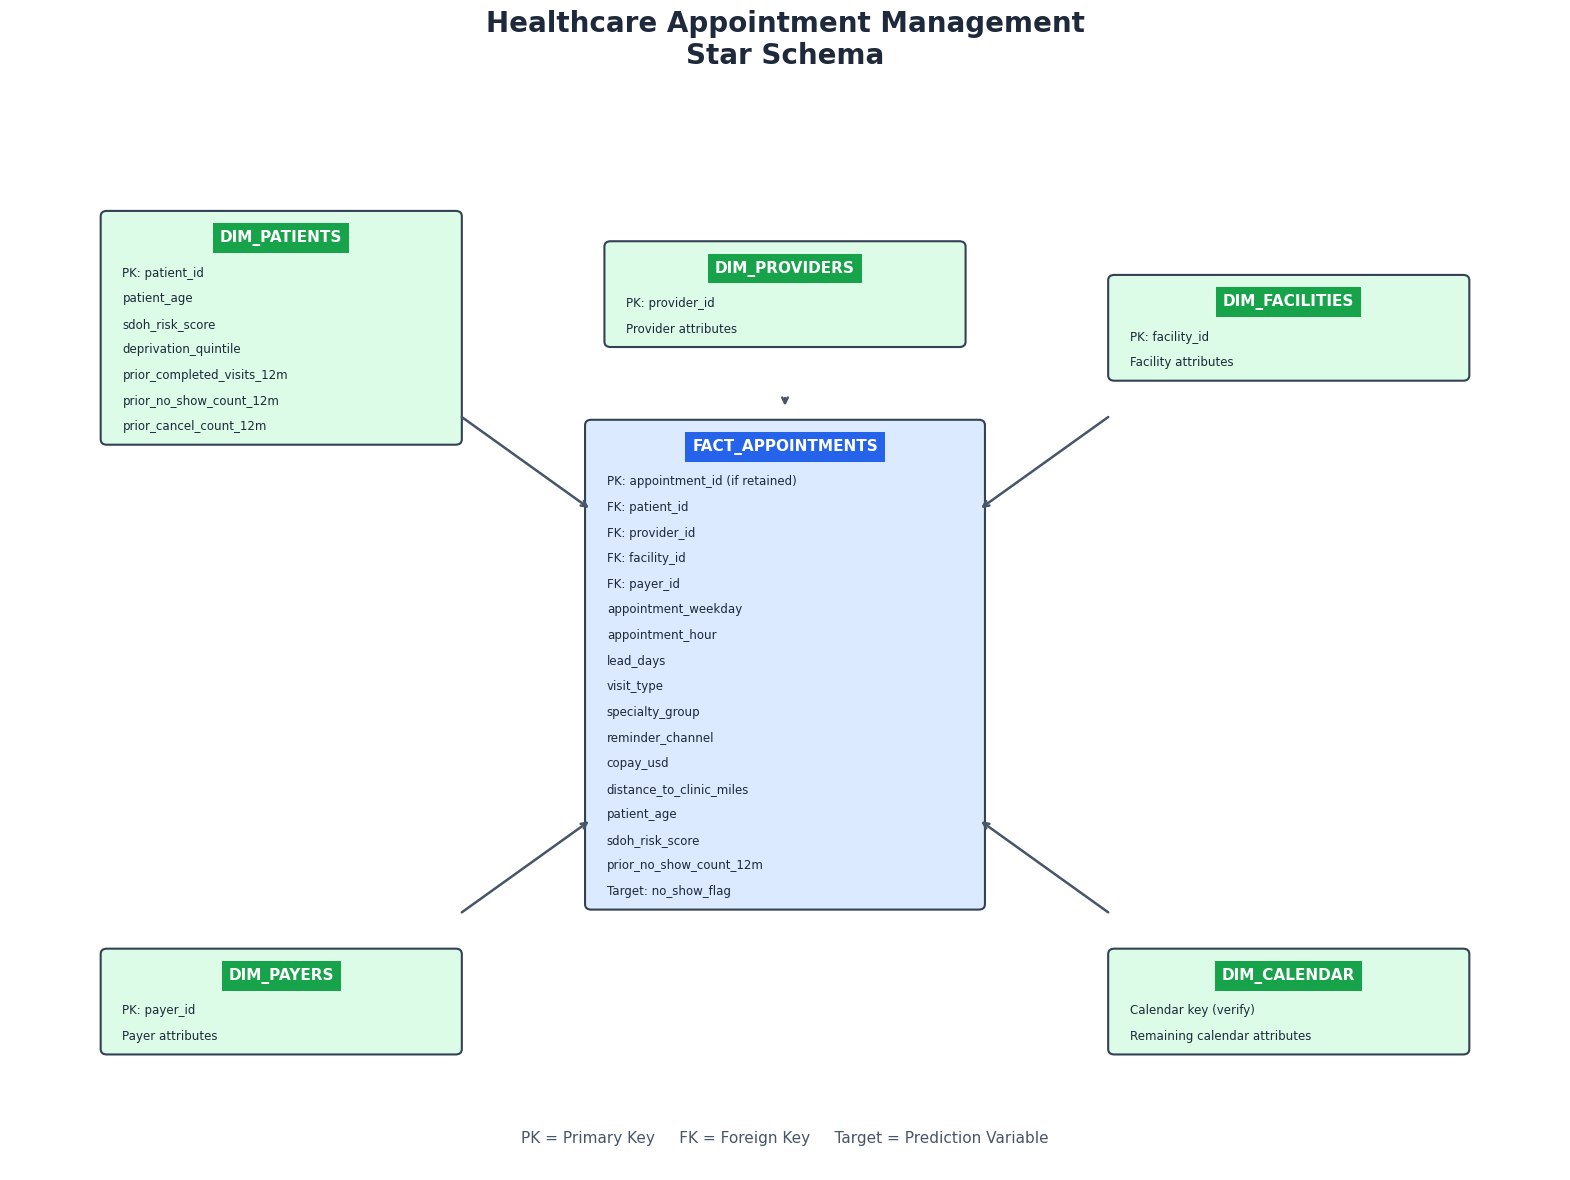

Schema generated successfully!
Saved as Healthcare_Star_Schema.png


In [1]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ==========================================
# 1. Create ER Diagram
# ==========================================

fig, ax = plt.subplots(figsize=(20, 14))

ax.set_xlim(0, 20)
ax.set_ylim(0, 16)
ax.axis('off')

# ==========================================
# 2. Function to Draw Database Tables
# ==========================================

def draw_table(x, y, title, columns, color,
               header_color, width=4.2):

    row_height = 0.38
    header_height = 0.65
    height = header_height + len(columns) * row_height

    # Table background
    box = FancyBboxPatch(
        (x - width/2, y - height/2),
        width,
        height,
        boxstyle="round,pad=0.08",
        facecolor=color,
        edgecolor="#334155",
        linewidth=1.5
    )

    ax.add_patch(box)

    # Header
    ax.text(
        x, y + height/2 - header_height/2,
        title,
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='white',
        bbox=dict(
            facecolor=header_color,
            edgecolor='none',
            boxstyle='square,pad=0.45'
        )
    )

    # Columns
    for i, column in enumerate(columns):

        column_y = (
            y + height/2 - header_height
            - (i + 0.5) * row_height
        )

        ax.text(
            x - width/2 + 0.2,
            column_y,
            column,
            ha='left',
            va='center',
            fontsize=8.5,
            color='#1E293B'
        )

    return height


# ==========================================
# 3. FACT_APPOINTMENTS Table
# ==========================================

fact_columns = [
    'PK: appointment_id (if retained)',
    'FK: patient_id',
    'FK: provider_id',
    'FK: facility_id',
    'FK: payer_id',
    'appointment_weekday',
    'appointment_hour',
    'lead_days',
    'visit_type',
    'specialty_group',
    'reminder_channel',
    'copay_usd',
    'distance_to_clinic_miles',
    'patient_age',
    'sdoh_risk_score',
    'prior_no_show_count_12m',
    'Target: no_show_flag'
]

fact_height = draw_table(
    10, 7.5,
    'FACT_APPOINTMENTS',
    fact_columns,
    '#DBEAFE',
    '#2563EB',
    width=5
)


# ==========================================
# 4. DIMENSION TABLES
# ==========================================

dimensions = {

    'DIM_PATIENTS': [
        'PK: patient_id',
        'patient_age',
        'sdoh_risk_score',
        'deprivation_quintile',
        'prior_completed_visits_12m',
        'prior_no_show_count_12m',
        'prior_cancel_count_12m'
    ],

    'DIM_PROVIDERS': [
        'PK: provider_id',
        'Provider attributes'
    ],

    'DIM_FACILITIES': [
        'PK: facility_id',
        'Facility attributes'
    ],

    'DIM_PAYERS': [
        'PK: payer_id',
        'Payer attributes'
    ],

    'DIM_CALENDAR': [
        'Calendar key (verify)',
        'Remaining calendar attributes'
    ]
}


# Positions of dimension tables
positions = {
    'DIM_PATIENTS': (3.5, 12.5),
    'DIM_PROVIDERS': (10, 13),
    'DIM_FACILITIES': (16.5, 12.5),
    'DIM_PAYERS': (3.5, 2.5),
    'DIM_CALENDAR': (16.5, 2.5)
}

# Draw all dimension tables
table_heights = {}

for table, columns in dimensions.items():

    x, y = positions[table]

    height = draw_table(
        x, y,
        table,
        columns,
        '#DCFCE7',
        '#16A34A',
        width=4.5
    )

    table_heights[table] = height


# ==========================================
# 5. Relationships
# ==========================================

connections = [
    ((5.8, 11.2), (7.5, 9.8)),
    ((10, 11.5), (10, 11.3)),
    ((14.2, 11.2), (12.5, 9.8)),
    ((5.8, 3.8), (7.5, 5.2)),
    ((14.2, 3.8), (12.5, 5.2))
]

for start, end in connections:

    ax.annotate(
        '',
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle='->',
            color='#475569',
            linewidth=1.8
        )
    )


# ==========================================
# 6. Title and Legend
# ==========================================

plt.title(
    'Healthcare Appointment Management\nStar Schema',
    fontsize=20,
    fontweight='bold',
    color='#1E293B',
    pad=20
)

ax.text(
    10, 0.4,
    'PK = Primary Key     FK = Foreign Key     Target = Prediction Variable',
    ha='center',
    fontsize=11,
    color='#475569'
)


# ==========================================
# 7. Save and Display
# ==========================================

plt.savefig(
    'Healthcare_Star_Schema.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("Schema generated successfully!")
print("Saved as Healthcare_Star_Schema.png")
